# Homework 4 — Evaluation

2026 cohort.  
Dataset: course_lead_scoring_2026.csv

# Setup and getting the data

Use the 2026 lead-scoring dataset, `course_lead_scoring_2026.csv`.

The target is `converted`: whether the client signed up to the platform.

In [1]:
import pandas as pd

df = pd.read_csv("../cohorts/2026/data/course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


# Data preparation

1. Check whether the features have missing values.

In [2]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

2. For categorical features, replace missing values with `'NA'`.

In [3]:
categorical = ["lead_source", "industry", "employment_status", "location"]
df[categorical] = df[categorical].fillna("NA")

3. For numerical features, replace missing values with `0.0`.

In [4]:
numerical = ["annual_income", "number_of_courses_viewed", "interaction_count", "lead_score"]
df[numerical] = df[numerical].fillna(0.0)

# Split the data

Split the data into 3 parts with these exact calls:

1. Split with these exact calls:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```

In [5]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

2. Take `converted` out as `y_train`, `y_val`, and `y_test`, then drop it from the feature dataframes.

In [6]:
y_train = df_train["converted"].values
y_val = df_val["converted"].values
y_test = df_test["converted"].values

del df_train["converted"]
del df_val["converted"]
del df_test["converted"]

# Question 1 ROC AUC feature importance

ROC AUC can also be used to evaluate how important a numerical variable is.

1. For each numerical variable, use it as the score and compute the AUC with `converted` as the ground truth. Use the training dataset only.

2. If the AUC is below 0.5, invert the variable by putting `-` in front, for example `-df_train['balance']`.

    AUC goes below 0.5 when the variable is negatively correlated with the target. Negating it turns that negative correlation positive.

In [7]:
from sklearn.metrics import roc_auc_score

for n in numerical:
    auc = roc_auc_score(y_train, df_train[n])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[n])
    print(n, auc)

annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


3. Which numerical variable has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

lead_score

# Question 2 Training the model

Apply one-hot encoding with `DictVectorizer` and train logistic regression.

1. One-hot encode the training data with `DictVectorizer`.

In [8]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
dv = DictVectorizer(sparse=False)
train_dict = df_train[categorical + numerical].to_dict(orient="records")
X_train = dv.fit_transform(train_dict)

2. Train logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

In [9]:
model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'liblinear'
,max_iter,1000
,multi_class,'deprecated'


3. What is the AUC of this model on the validation dataset? Round to 3 digits.

- 0.532
- 0.632
- 0.732
- 0.832

In [10]:
val_dict = df_val[categorical + numerical].to_dict(orient="records")
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
round(roc_auc_score(y_val, y_pred), 3)

/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


0.732

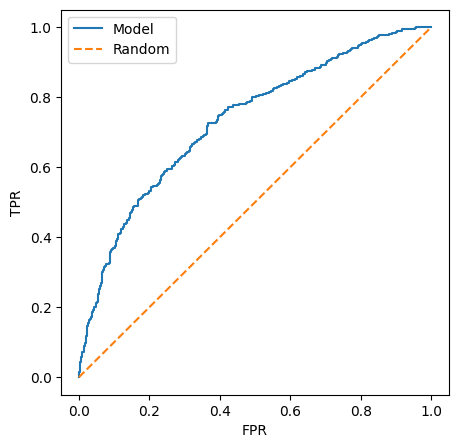

In [11]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_val, y_pred)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label="Model")
plt.plot([0, 1], [0, 1], label="Random", linestyle="--")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()

# Question 3 Precision and Recall

Compute precision and recall for the model from Question 2.

1. Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01.

In [12]:
import numpy as np
import pandas as pd

def tpr_fpr_dataframe(y_val, y_pred):
    scores = []
    thresholds = np.arange(0, 1.01, 0.01)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()
        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
    df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)


    return df_scores

# 呼叫 function



2. For each threshold, compute precision and recall.

In [13]:
df_scores = tpr_fpr_dataframe(y_val, y_pred)
print(df_scores["precision"])
print(df_scores["recall"])

0      0.586
1      0.586
2      0.586
3      0.586
4      0.586
       ...  
96     1.000
97       NaN
98       NaN
99       NaN
100      NaN
Name: precision, Length: 101, dtype: float64
0      1.000000
1      1.000000
2      1.000000
3      1.000000
4      1.000000
         ...   
96     0.001706
97     0.000000
98     0.000000
99     0.000000
100    0.000000
Name: recall, Length: 101, dtype: float64


3. Plot them.

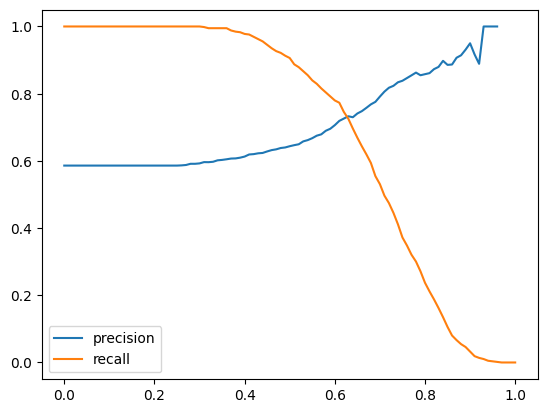

In [14]:
plt.plot(df_scores.threshold, df_scores['precision'], label='precision')
plt.plot(df_scores.threshold, df_scores['recall'], label='recall')
plt.legend()

4. At which threshold do the precision and recall curves intersect?

Ignore thresholds where both metrics are zero. Choose the threshold with the smallest absolute difference between precision and recall.

- 0.43
- 0.63
- 0.73
- 0.83

In [15]:
candidates = df_scores[(df_scores.precision != 0) | (df_scores.recall != 0)].copy()
candidates["diff"] = (candidates.precision - candidates.recall).abs()
candidates.loc[candidates["diff"].idxmin(), ["threshold", "precision", "recall", "diff"]]

threshold    0.630000
precision    0.732759
recall       0.725256
diff         0.007503
Name: 63, dtype: float64

# Question 4 F1 score

Precision and recall conflict: when one grows, the other goes down. F1 combines both.

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

$P$ is precision and $R$ is recall.

1. Compute F1 for all thresholds from 0.0 to 1.0 with step 0.01.

In [16]:
df_scores = tpr_fpr_dataframe(y_val, y_pred)
f1 = 2 * (df_scores.precision * df_scores.recall) / (df_scores.precision + df_scores.recall)
print(f1)

0      0.738966
1      0.738966
2      0.738966
3      0.738966
4      0.738966
         ...   
96     0.003407
97          NaN
98          NaN
99          NaN
100         NaN
Length: 101, dtype: float64


2. At which threshold is F1 maximal?

- 0.21
- 0.41
- 0.61
- 0.81

In [17]:
df_scores["f1"] = (
    2 * df_scores.precision * df_scores.recall
    / (df_scores.precision + df_scores.recall)
)
df_scores["f1"] = df_scores["f1"].fillna(0)
df_scores.loc[df_scores.f1.idxmax(), ["threshold", "f1"]]

threshold    0.410000
f1           0.757616
Name: 41, dtype: float64

In [18]:
print(df_train)

         lead_source    industry employment_status       location  \
4740        paid_ads  technology          employed           asia   
1452        paid_ads      retail          employed           asia   
2846              NA     finance          employed             NA   
4670        paid_ads     finance          employed             NA   
168   organic_search     finance          employed           asia   
...              ...         ...               ...            ...   
253         paid_ads     finance          employed  north_america   
1366          events  technology          employed           asia   
753           events      retail        unemployed           asia   
4990  organic_search  healthcare        unemployed  south_america   
357   organic_search   education     self_employed         europe   

      annual_income  number_of_courses_viewed  interaction_count  lead_score  
4740        80198.0                         5                  9        0.91  
1452        5

# Question 5 5-Fold CV

Use `KFold` to evaluate the model on 5 different folds:

```python
KFold(n_splits=5, shuffle=True, random_state=1)
```

1. Iterate over the folds of `df_full_train`. Split each fold into train and validation.

In [19]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient="records")

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient="records")

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred


def auc_score(df_val, y_val, dv, model):
    y_pred = predict(df_val, dv, model)
    return roc_auc_score(y_val, y_pred)

In [20]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train, C=1.0)
    scores.append(auc_score(df_val, y_val, dv, model))

scores

/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.1

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

3. Use AUC to evaluate the model on each validation fold.

4. How large is the standard deviation of the scores across folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [21]:
np.std(scores)

np.float64(0.006853233151022138)

# Question 6 Hyperparameter Tuning

Use the same 5-fold cross-validation to find the best parameter `C`.

1. Initialize `KFold` with the same parameters as Question 5.

In [22]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

2. Iterate over these `C` values: `[0.000001, 0.001, 1]`.

Train with:

```python
LogisticRegression(solver='liblinear', C=C, max_iter=1000)
```

In [23]:
scores_by_c = {}

for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        scores.append(auc_score(df_val, y_val, dv, model))

    scores_by_c[C] = scores

/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.1

/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.1

/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.1

3. For each `C`, compute the mean ROC AUC and the standard deviation. Round both to 3 decimal digits.

In [24]:
for C, scores in scores_by_c.items():
    print(f"C={C} mean={np.mean(scores):.3f} std={np.std(scores):.3f}")

C=1e-06 mean=0.617 std=0.019
C=0.001 mean=0.749 std=0.010
C=1 mean=0.732 std=0.007


4. Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If several values tie, select the one with the lowest standard deviation. If they still tie, select the smallest `C`.

In [25]:
best_c = None
best_mean = None
best_std = None

for C, scores in scores_by_c.items():
    mean = round(np.mean(scores), 3)
    std = round(np.std(scores), 3)

    if (
        best_c is None
        or mean > best_mean
        or (mean == best_mean and std < best_std)
        or (mean == best_mean and std == best_std and C < best_c)
    ):
        best_c = C
        best_mean = mean
        best_std = std

best_c, best_mean, best_std

(0.001, np.float64(0.749), np.float64(0.01))